In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import load_model

housing_df = pd.read_csv('../data/raw/HOUSEPRICES.csv')
income_df = pd.read_csv('../data/raw/MEDIANINCOME.csv')
population_df = pd.read_csv('../data/raw/POPULATION.csv')
cpi_df = pd.read_csv('../data/raw/CPI.csv')
unemployment_df = pd.read_csv('../data/raw/UNEMPLOYMENT.csv')
date_columns = housing_df.columns[8:]

In [3]:
housing_melted = pd.melt(
    housing_df,
    id_vars=['RegionID', 'RegionName', 'RegionType', 'StateName', 'State'],
    value_vars=date_columns,
    var_name='Date',
    value_name='Price'
)
housing_melted['Date'] = pd.to_datetime(housing_melted['Date'])

housing_avg = housing_melted.groupby('Date')['Price'].mean().reset_index()
housing_avg = housing_avg.rename(columns={'Price': 'AvgHousePrice'})

housing_avg.set_index('Date', inplace=True)

Forecasted Housing Prices for the next 10 months:
         Date  Scaled_Predicted_Price  Actual_Predicted_Price_USD
0  2021-02-28                0.929175               250407.609375
1  2021-03-31                0.948982               252462.156250
2  2021-04-30                0.966842               254314.828125
3  2021-05-31                0.989432               256658.046875
4  2021-06-30                1.009277               258716.625000
5  2021-07-31                1.030332               260900.687500
6  2021-08-31                1.057639               263733.187500
7  2021-09-30                1.079559               266006.968750
8  2021-10-31                1.102709               268408.312500
9  2021-11-30                1.120359               270239.156250
10 2021-12-31                1.134563               271712.500000


<Figure size 1200x600 with 0 Axes>

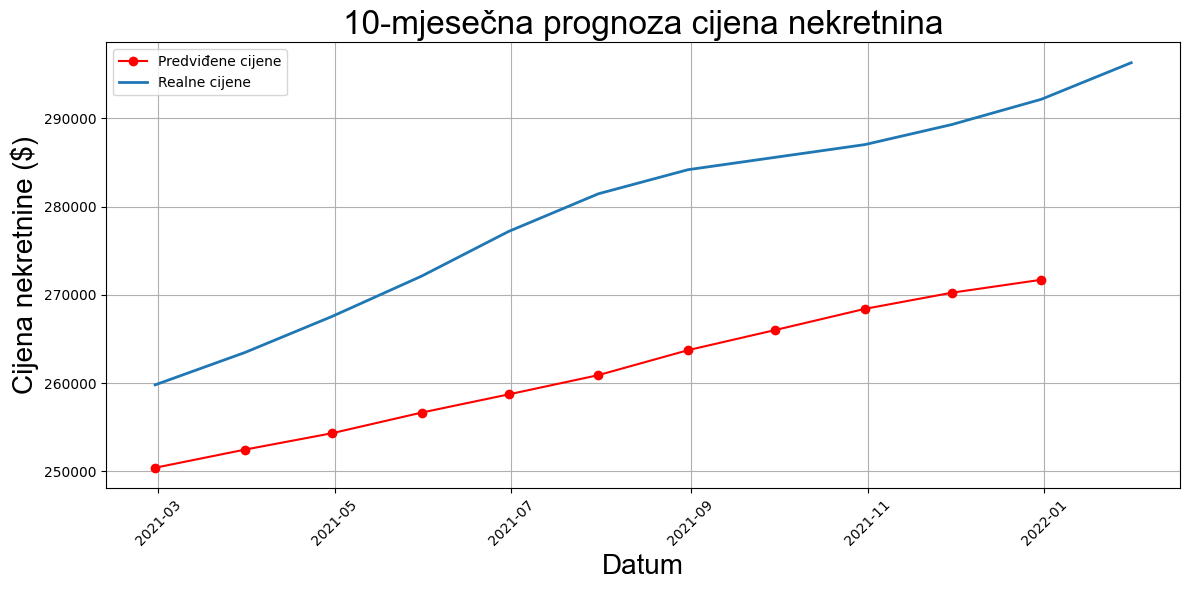

In [4]:
housing_avg_filtered = housing_avg.loc['2021-02-01':'2022-01-31']

plt.figure(figsize=(12, 6))

model = load_model('house_price_lstm_model.keras')

df = pd.read_csv('../data/processed/scaled_data.csv', index_col=0, parse_dates=True)

seq_length = 12
feature_cols = [col for col in df.columns if col != 'AvgHousePrice']

last_sequence = df[feature_cols].iloc[-seq_length:].values
last_sequence = last_sequence.reshape(1, seq_length, len(feature_cols))

forecast_months = 11
scaled_predictions = []

last_date = df.index[-1]
future_dates = pd.date_range(start=last_date, periods=forecast_months+1, freq='ME')[1:]

current_batch = last_sequence.copy()

for i in range(forecast_months):
    next_pred = model.predict(current_batch, verbose=0)[0][0]
    scaled_predictions.append(next_pred)
    
    next_seq = current_batch[0, 1:, :].copy()
    
    new_row = next_seq[-1].copy()
    
    new_row[0] = next_pred
    
    current_batch = np.vstack([next_seq, new_row.reshape(1, -1)])
    current_batch = current_batch.reshape(1, seq_length, len(feature_cols))

original_min = 154024.15
original_max = 257754.29 

actual_price_predictions = []
for scaled_val in scaled_predictions:
    actual_price = scaled_val * (original_max - original_min) + original_min
    actual_price_predictions.append(actual_price)

forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Scaled_Predicted_Price': scaled_predictions,
    'Actual_Predicted_Price_USD': actual_price_predictions
})

print("Forecasted Housing Prices for the next 10 months:")
print(forecast_df)

plt.figure(figsize=(12, 6))
font = {'family':'arial','color':'black','size':20}
titleFont = {'family':'arial','color':'black','size':24}
plt.plot(forecast_df['Date'], forecast_df['Actual_Predicted_Price_USD'], 'r-o', label='Predviđene cijene')
plt.plot(housing_avg_filtered.index, housing_avg_filtered['AvgHousePrice'], linewidth=2, color='#1f77b4', label='Realne cijene')
plt.title('10-mjesečna prognoza cijena nekretnina', fontdict = titleFont)
plt.xlabel('Datum', fontdict = font)
plt.ylabel('Cijena nekretnine ($)', fontdict = font)
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.legend()
plt.show()

In [5]:
income_df['observation_date'] = pd.to_datetime(income_df['observation_date'])
income_df.set_index('observation_date', inplace=True)
income_df = income_df.resample('MS').ffill()
print(income_df)

                  MedianHouseholdIncome
observation_date                       
1984-01-01                        58930
1984-02-01                        58930
1984-03-01                        58930
1984-04-01                        58930
1984-05-01                        58930
...                                 ...
2022-09-01                        77540
2022-10-01                        77540
2022-11-01                        77540
2022-12-01                        77540
2023-01-01                        80610

[469 rows x 1 columns]


In [6]:
population_df['observation_date'] = pd.to_datetime(population_df['observation_date'])
population_df.set_index('observation_date', inplace=True)

In [7]:
cpi_df['observation_date'] = pd.to_datetime(cpi_df['observation_date'])
cpi_df.set_index('observation_date', inplace=True)

In [8]:
unemployment_us = unemployment_df[unemployment_df['Country Name'] == 'United States']

In [9]:
unemployment_years = unemployment_us.iloc[:, 2:].T

In [10]:
unemployment_years.index = pd.to_datetime(unemployment_years.index, format='%Y')
unemployment_years.columns = ['Unemployment']

In [11]:
unemployment_monthly = unemployment_years.resample('MS').ffill()

In [12]:
income_df = income_df.resample('ME').last()
population_df = population_df.resample('ME').last()
cpi_df = cpi_df.resample('ME').last()
unemployment_monthly = unemployment_monthly.resample('ME').last()

common_start = '2000-01-31'

common_end = min(
    housing_avg.index.max(),
    income_df.index.max(),
    population_df.index.max(),
    cpi_df.index.max(),
    unemployment_monthly.index.max()
)

housing_filtered = housing_avg[common_start:common_end]
income_filtered = income_df[common_start:common_end]
population_filtered = population_df[common_start:common_end]
cpi_filtered = cpi_df[common_start:common_end]
unemployment_filtered = unemployment_monthly[common_start:common_end]

In [13]:
merged_data = pd.concat([
    housing_filtered,
    income_filtered,
    population_filtered['POPTHM'].rename('Population'),
    cpi_filtered['CPI'],
    unemployment_filtered
], axis=1)

In [14]:
merged_data.ffill(inplace=True)

In [13]:
print(merged_data)

            AvgHousePrice  MedianHouseholdIncome  Population      CPI  \
2000-01-31  143033.555458                  70020      281083  165.600   
2000-02-29  143158.534386                  70020      281299  166.500   
2000-03-31  143410.996369                  70020      281531  167.900   
2000-04-30  144223.363551                  70020      281763  168.000   
2000-05-31  145047.533509                  70020      281996  168.200   
...                   ...                    ...         ...      ...   
2020-09-30  242279.531817                  79560      332017  254.004   
2020-10-31  245963.696617                  79560      332092  254.076   
2020-11-30  250154.083684                  79560      332129  253.826   
2020-12-31  254116.736227                  79560      332113  254.081   
2021-01-31  257754.286018                  79260      332058  255.296   

            Unemployment  
2000-01-31          3.99  
2000-02-29          3.99  
2000-03-31          3.99  
2000-04-30     

In [14]:
for lag in range(1, 13):
    merged_data[f'Price_Lag_{lag}'] = merged_data['AvgHousePrice'].shift(lag)

In [15]:
merged_data['Price_3M_MA'] = merged_data['AvgHousePrice'].rolling(window=3).mean()
merged_data['Price_6M_MA'] = merged_data['AvgHousePrice'].rolling(window=6).mean()
merged_data['Price_12M_MA'] = merged_data['AvgHousePrice'].rolling(window=12).mean()

In [16]:
merged_data['Month'] = merged_data.index.month
merged_data['Year'] = merged_data.index.year

In [17]:
month_dummies = pd.get_dummies(merged_data['Month'], prefix='Month', drop_first=True)
merged_data = pd.concat([merged_data, month_dummies], axis=1)
print(merged_data)

            AvgHousePrice  MedianHouseholdIncome  Population      CPI  \
2000-01-31  143033.555458                  70020      281083  165.600   
2000-02-29  143158.534386                  70020      281299  166.500   
2000-03-31  143410.996369                  70020      281531  167.900   
2000-04-30  144223.363551                  70020      281763  168.000   
2000-05-31  145047.533509                  70020      281996  168.200   
...                   ...                    ...         ...      ...   
2020-09-30  242279.531817                  79560      332017  254.004   
2020-10-31  245963.696617                  79560      332092  254.076   
2020-11-30  250154.083684                  79560      332129  253.826   
2020-12-31  254116.736227                  79560      332113  254.081   
2021-01-31  257754.286018                  79260      332058  255.296   

            Unemployment    Price_Lag_1    Price_Lag_2    Price_Lag_3  \
2000-01-31          3.99            NaN           

In [18]:
merged_data['YoY_Price_Change'] = merged_data['AvgHousePrice'].pct_change(12)
merged_data['YoY_Population_Change'] = merged_data['Population'].pct_change(12)
merged_data['YoY_Income_Change'] = merged_data['MedianHouseholdIncome'].pct_change(12)

In [19]:
merged_data_clean = merged_data.dropna()

In [20]:
print(merged_data_clean)

            AvgHousePrice  MedianHouseholdIncome  Population      CPI  \
2001-01-31  154024.146023                  68870      283960  171.700   
2001-02-28  155039.976457                  68870      284166  172.400   
2001-03-31  156035.123228                  68870      284380  172.600   
2001-04-30  157078.065681                  68870      284602  173.500   
2001-05-31  158057.794671                  68870      284834  174.400   
...                   ...                    ...         ...      ...   
2020-09-30  242279.531817                  79560      332017  254.004   
2020-10-31  245963.696617                  79560      332092  254.076   
2020-11-30  250154.083684                  79560      332129  253.826   
2020-12-31  254116.736227                  79560      332113  254.081   
2021-01-31  257754.286018                  79260      332058  255.296   

            Unemployment    Price_Lag_1    Price_Lag_2    Price_Lag_3  \
2001-01-31          4.73  153011.794451  151811.84

In [21]:
features = [
    'AvgHousePrice', 'MedianHouseholdIncome', 'Population', 'CPI', 'Unemployment',
    'Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3', 'Price_Lag_6', 'Price_Lag_12',
    'Price_3M_MA', 'Price_6M_MA', 'Price_12M_MA',
    'YoY_Price_Change', 'YoY_Population_Change', 'YoY_Income_Change'
] + [col for col in merged_data.columns if col.startswith('Month_')]

In [23]:
house_price_min = merged_data_clean['AvgHousePrice'].min()
house_price_max = merged_data_clean['AvgHousePrice'].max()

print(f"Minimum house price: ${house_price_min:,.2f}")
print(f"Maximum house price: ${house_price_max:,.2f}")

Minimum house price: $154,024.15
Maximum house price: $257,754.29


In [63]:
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(merged_data_clean[features])
scaled_df = pd.DataFrame(scaled_data, columns=features, index=merged_data_clean.index)

In [64]:
print(scaled_df)

            AvgHousePrice  MedianHouseholdIncome  Population       CPI  \
2001-01-31       0.000000               0.202327    0.000000  0.000000   
2001-02-28       0.009793               0.202327    0.004277  0.008374   
2001-03-31       0.019387               0.202327    0.008719  0.010766   
2001-04-30       0.029441               0.202327    0.013328  0.021532   
2001-05-31       0.038886               0.202327    0.018144  0.032298   
...                   ...                    ...         ...       ...   
2020-09-30       0.850817               0.893342    0.997675  0.984545   
2020-10-31       0.886334               0.893342    0.999232  0.985406   
2020-11-30       0.926731               0.893342    1.000000  0.982415   
2020-12-31       0.964933               0.893342    0.999668  0.985466   
2021-01-31       1.000000               0.873950    0.998526  1.000000   

            Unemployment  Price_Lag_1  Price_Lag_2  Price_Lag_3  Price_Lag_6  \
2001-01-31      0.177852     0.

In [65]:
def create_sequences(data, target_col, seq_length=12):
    X, y = [], []
    data_array = data.values
    for i in range(len(data_array) - seq_length):
        X.append(data_array[i:i+seq_length])
        y.append(data_array[i+seq_length, data.columns.get_loc(target_col)])
    return np.array(X), np.array(y)

In [67]:
X, y = create_sequences(scaled_df, 'AvgHousePrice', seq_length=12)

In [73]:
split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

In [74]:
print(X_test)

[[[0.43523999 0.50290886 0.83250638 ... 0.         0.         0.        ]
  [0.44012845 0.50290886 0.83663767 ... 0.         0.         0.        ]
  [0.44662323 0.50290886 0.84112188 ... 0.         0.         0.        ]
  ...
  [0.48696979 0.58629606 0.87070523 ... 0.         0.         0.        ]
  [0.48498082 0.58629606 0.8737985  ... 0.         0.         0.        ]
  [0.49479985 0.58629606 0.87705786 ... 0.         0.         0.        ]]

 [[0.44012845 0.50290886 0.83663767 ... 0.         0.         0.        ]
  [0.44662323 0.50290886 0.84112188 ... 0.         0.         0.        ]
  [0.4502321  0.50290886 0.8457099  ... 0.         0.         0.        ]
  ...
  [0.48498082 0.58629606 0.8737985  ... 0.         0.         0.        ]
  [0.49479985 0.58629606 0.87705786 ... 0.         0.         0.        ]
  [0.5055511  0.58629606 0.88046254 ... 0.         0.         0.        ]]

 [[0.44662323 0.50290886 0.84112188 ... 0.         0.         0.        ]
  [0.4502321  0.502908

In [76]:
print(y_test)

[0.5055511  0.51466947 0.52313951 0.53044608 0.53806777 0.54650607
 0.55578625 0.56556937 0.57543436 0.58528196 0.58753689 0.60053676
 0.61309984 0.62627707 0.63507544 0.64437005 0.65301474 0.66196761
 0.66751927 0.67365085 0.67938948 0.68572036 0.66717392 0.67638916
 0.6851496  0.69233231 0.69860523 0.70451631 0.71081596 0.71509176
 0.7217641  0.73077304 0.74175513 0.75211876 0.76264076 0.77635528
 0.79045139 0.79859957 0.80155174 0.80638139 0.82186296 0.85081719
 0.88633401 0.92673101 0.96493257 1.        ]


In [77]:
scaled_df.to_csv('../data/processed/scaled_data.csv', index=True)